# 02 · Exploratory analysis
Trend, California–U.S. spread, crude link, seasonality (STL), stationarity tests, ACF/PACF and crude→gasoline cross-correlation.
Figures are saved to `results/figures/` and reused in the report, slides and dashboard. Statistical tests use the training sample only (before July 2025).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
import plots; plots.setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
df = load_weekly()
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
train = df[df.split == "train"]
test_start, end = TEST_START, df.index[-1]
findings = {}

## Prices since 2000

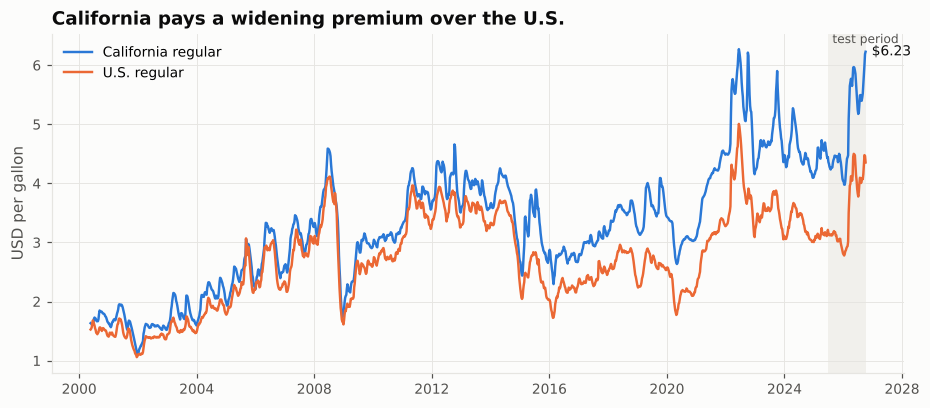

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.index, df.ca_gas, color=plots.SERIES["ca_gas"], label="California regular")
ax.plot(df.index, df.us_gas, color=plots.SERIES["us_gas"], label="U.S. regular")
plots.shade_test(ax, test_start, end)
ax.set_ylabel("USD per gallon"); ax.set_title("California pays a widening premium over the U.S.")
ax.legend(loc="upper left")
ax.annotate(f"${df.ca_gas.iloc[-1]:.2f}", (end, df.ca_gas.iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9, color=plots.INK, va="center")
plots.save(fig, FIG_DIR / "fig01_prices.png"); fig

{'spread_2000_2004': 0.22, 'spread_2020_2024': 1.14, 'spread_latest_year': 1.48}


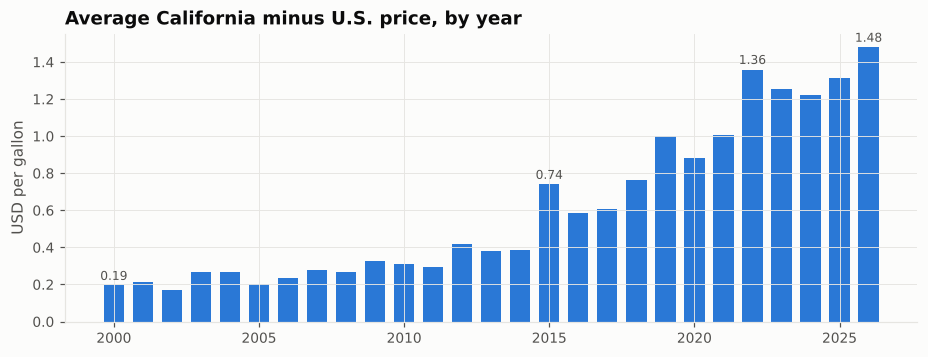

In [3]:
spread_year = df.ca_us_spread.groupby(df.index.year).mean()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(spread_year.index, spread_year.values, color=plots.SERIES["ca_gas"], width=0.7)
ax.set_ylabel("USD per gallon"); ax.set_title("Average California minus U.S. price, by year")
for yr in [2000, 2015, 2022, spread_year.index.max()]:
    ax.text(yr, spread_year[yr] + 0.03, f"{spread_year[yr]:.2f}", ha="center", fontsize=8, color=plots.INK2)
plots.save(fig, FIG_DIR / "fig02_spread.png")
findings["spread_2000_2004"] = float(spread_year.loc[2000:2004].mean())
findings["spread_2020_2024"] = float(spread_year.loc[2020:2024].mean())
findings["spread_latest_year"] = float(spread_year.iloc[-1])
print({k: round(v, 2) for k, v in findings.items()}); fig

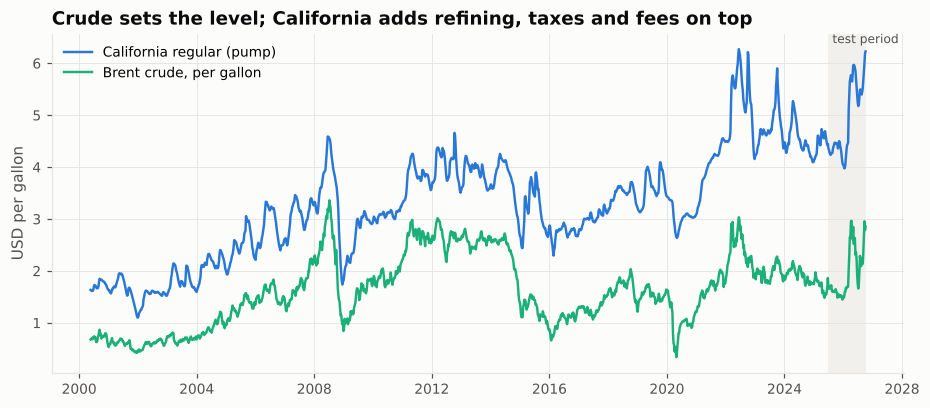

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.index, df.ca_gas, color=plots.SERIES["ca_gas"], label="California regular (pump)")
ax.plot(df.index, df.brent_gal, color=plots.SERIES["brent"], label="Brent crude, per gallon")
plots.shade_test(ax, test_start, end)
ax.set_ylabel("USD per gallon"); ax.set_title("Crude sets the level; California adds refining, taxes and fees on top")
ax.legend(loc="upper left")
plots.save(fig, FIG_DIR / "fig03_crude.png"); fig

## Seasonality: STL with a 52-week season (log prices, training sample)

{1: -6.43, 2: -3.57, 3: 1.25, 4: 5.5, 5: 6.74, 6: 2.87, 7: 0.95, 8: 1.1, 9: 1.24, 10: -0.39, 11: -1.65, 12: -6.66}
{'summer_premium_pct': 7.644, 'seasonal_peak_month': 5, 'seasonal_strength': 0.22}


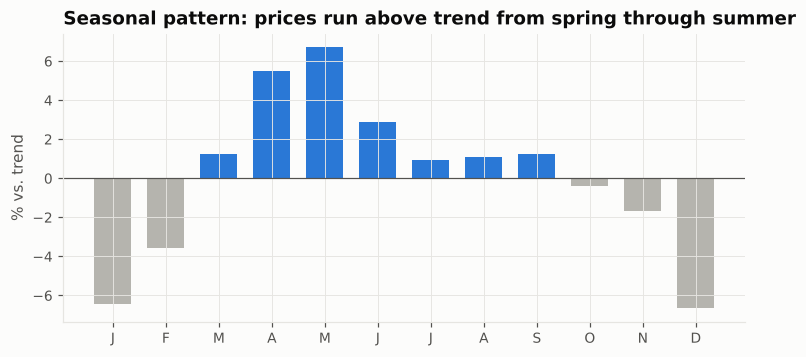

In [5]:
stl = STL(np.log(train.ca_gas), period=52, robust=True).fit()
seas = pd.Series(np.exp(stl.seasonal) - 1, index=train.index)
by_month = seas.groupby(seas.index.month).mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
cols = [plots.SERIES["ca_gas"] if v > 0 else "#b5b4ae" for v in by_month.values]
ax.bar(by_month.index, by_month.values, color=cols, width=0.7)
ax.axhline(0, color=plots.INK2, lw=0.8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("% vs. trend"); ax.set_title("Seasonal pattern: prices run above trend from spring through summer")
plots.save(fig, FIG_DIR / "fig04_seasonal.png")
findings["summer_premium_pct"] = float(by_month.loc[4:9].mean() - by_month.loc[[1, 2, 11, 12]].mean())
findings["seasonal_peak_month"] = int(by_month.idxmax())
findings["seasonal_strength"] = float(max(0, 1 - np.var(stl.resid) / np.var(stl.resid + stl.seasonal)))
print(by_month.round(2).to_dict()); print({k: round(findings[k], 3) for k in ["summer_premium_pct", "seasonal_peak_month", "seasonal_strength"]}); fig

## Stationarity: ADF (H0 unit root) and KPSS (H0 stationary)

In [6]:
rows = []
for name, s in {"log CA price": np.log(train.ca_gas), "Δ log CA price": np.log(train.ca_gas).diff(),
                "log Brent": np.log(train.brent), "Δ log Brent": np.log(train.brent).diff(),
                "CA–US spread": train.ca_us_spread}.items():
    s = s.dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    rows.append({"series": name, "ADF p": adf_p, "KPSS p": kpss_p,
                 "verdict": "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else ("unit root" if adf_p > 0.05 and kpss_p < 0.05 else "mixed")})
unit = pd.DataFrame(rows).set_index("series").round(3)
unit.to_csv(RES_DIR / "unit_root_tests.csv"); unit

/tmp/ipykernel_3750/336262510.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_p = kpss(s, regression="c", nlags="auto")[1]
/tmp/ipykernel_3750/336262510.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(s, regression="c", nlags="auto")[1]
/tmp/ipykernel_3750/336262510.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_p = kpss(s, regression="c", nlags="auto")[1]
/tmp/ipykernel_3750/336262510.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(s, regression="c", n

,ADF p,KPSS p,verdict
series,,,
log CA price,0.142,0.01,unit root
Δ log CA price,0.000,0.10,stationary
log Brent,0.117,0.01,unit root
Δ log Brent,0.000,0.10,stationary
CA–US spread,0.734,0.01,unit root


Levels have a unit root; first differences are stationary → models use d = 1 on log prices (ARIMA selects this automatically). KPSS p-values are truncated at 0.01/0.10 by the test tables.

## ACF / PACF of weekly log changes

0.643 0.386


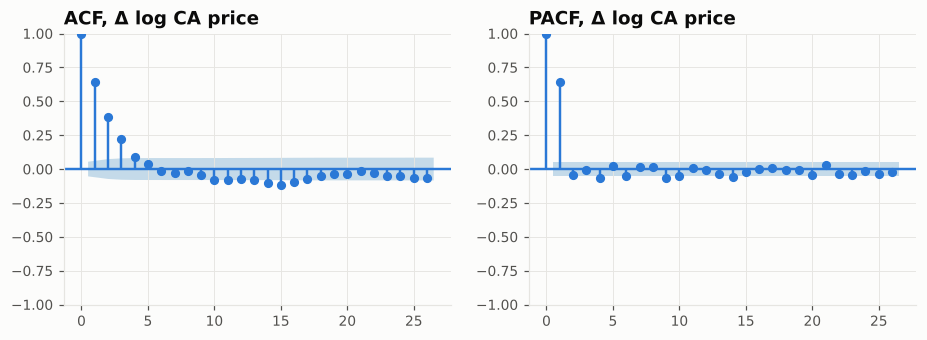

In [7]:
dl = np.log(train.ca_gas).diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
plot_acf(dl, lags=26, ax=ax[0], color=plots.SERIES["ca_gas"], vlines_kwargs={"colors": plots.SERIES["ca_gas"]})
plot_pacf(dl, lags=26, ax=ax[1], color=plots.SERIES["ca_gas"], vlines_kwargs={"colors": plots.SERIES["ca_gas"]}, method="ywm")
ax[0].set_title("ACF, Δ log CA price"); ax[1].set_title("PACF, Δ log CA price")
plots.save(fig, FIG_DIR / "fig05_acf.png")
findings["acf_lag1"] = float(dl.autocorr(1)); findings["acf_lag2"] = float(dl.autocorr(2))
print(round(findings["acf_lag1"], 3), round(findings["acf_lag2"], 3)); fig

Strong positive autocorrelation in weekly changes (price moves persist for several weeks) with a PACF that cuts off after a few lags → low-order AR terms on differenced log prices.

## Does crude lead the pump? Cross-correlation of weekly changes

[0.339 0.345 0.261 0.211 0.163 0.127 0.061 0.038 0.023]


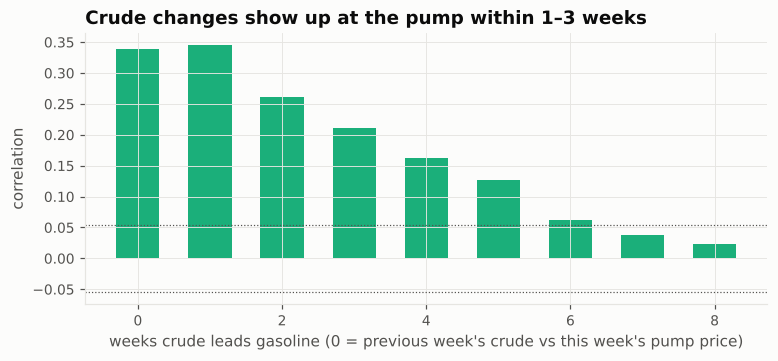

In [8]:
d = train[["dlog_ca_gas", "dlog_brent"]].dropna()
lags = range(0, 9)
cc = [d.dlog_ca_gas.corr(d.dlog_brent.shift(k)) for k in lags]   # corr(gas_t, crude_{t-k})
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(list(lags), cc, color=plots.SERIES["brent"], width=0.6)
ci = 1.96 / np.sqrt(len(d)); ax.axhline(ci, color=plots.INK2, ls=":", lw=0.8); ax.axhline(-ci, color=plots.INK2, ls=":", lw=0.8)
ax.set_xlabel("weeks crude leads gasoline (0 = previous week's crude vs this week's pump price)")
ax.set_ylabel("correlation"); ax.set_title("Crude changes show up at the pump within 1–3 weeks")
plots.save(fig, FIG_DIR / "fig06_ccf.png")
findings["ccf"] = [float(x) for x in cc]; findings["ccf_peak_lag"] = int(np.argmax(cc))
print(np.round(cc, 3)); fig

In [9]:
import json
json.dump(findings, open(RES_DIR / "eda_findings.json", "w"), indent=1)
findings

{'spread_2000_2004': 0.2225516237300435,
 'spread_2020_2024': 1.1445446298984034,
 'spread_latest_year': 1.4791750000000001,
 'summer_premium_pct': 7.643581250268633,
 'seasonal_peak_month': 5,
 'seasonal_strength': 0.2195803869771924,
 'acf_lag1': 0.6429534423948926,
 'acf_lag2': 0.38551724691838196,
 'ccf': [0.339286158180216,
  0.34464024810141214,
  0.2614713915779282,
  0.21056798197706564,
  0.16321836479143456,
  0.127152759364179,
  0.06149100638105505,
  0.03817894505143728,
  0.02334548098838464],
 'ccf_peak_lag': 1}